# A quick introduction to mpstab

mpstab simulates quantum circuits with a *hybrid stabilizer-MPS* representation: the Clifford part of a circuit is handled by a fast stabilizer simulator, and only the non-Clifford ("magic") gates are pushed into a matrix product state (MPS). In this tutorial you will learn how to wrap a qibo circuit in an `HSMPO` surrogate, compute expectation values, check them against an exact simulation, and see why magic gates, not qubits, set the cost of a simulation.

## Setup

We build circuits with [qibo](https://qibo.science) and simulate them with mpstab's `HSMPO` class. We also load the shared plot style used by all mpstab tutorials.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo import Circuit, gates, hamiltonians, set_backend
from qibo.symbols import X, Z

from mpstab import HSMPO, pauli_string_to_hamiltonian
from mpstab.models.ansatze import HardwareEfficient
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_backend("numpy")  # qibo's exact statevector simulator, used as a reference
set_style()
np.random.seed(42)

## A first circuit

We prepare a GHZ-like entangled state with Hadamard and CNOT gates, then add a layer of $R_Y(\theta)$ rotations and a chain of CZ gates. The rotations are the only non-Clifford gates. Passing the circuit to `HSMPO` splits it into its Clifford and magic parts and builds the MPS once.

In [2]:
nqubits = 6

def build_circuit(theta):
    circuit = Circuit(nqubits)
    circuit.add(gates.H(0))
    for q in range(nqubits - 1):
        circuit.add(gates.CNOT(q, q + 1))
    for q in range(nqubits):
        circuit.add(gates.RY(q, theta=theta))
    for q in range(nqubits - 1):
        circuit.add(gates.CZ(q, q + 1))
    return circuit

circuit = build_circuit(theta=0.3)
circuit.draw()

surrogate = HSMPO(circuit, progress=False)
print(f"Clifford gates: {surrogate.n_clifford_gates}, magic gates: {surrogate.n_magic_gates}")

0: ─H─o─────────RY─o─────────
1: ───X─o───────RY─Z─o───────
2: ─────X─o─────RY───Z─o─────
3: ───────X─o───RY─────Z─o───
4: ─────────X─o─RY───────Z─o─
5: ───────────X─RY─────────Z─
Clifford gates: 11, magic gates: 6


## Expectation values

`expectation` takes a Pauli string, with qubit 0 as the leftmost character. For observables made of several terms you can pass a `{pauli_string: coefficient}` dictionary or a qibo `SymbolicHamiltonian`. Here we measure the correlator $Z_0 Z_5$ and the energy of a transverse-field Ising chain, $H = \sum_i Z_i Z_{i+1} + \tfrac12 \sum_i X_i$.

In [3]:
zz = surrogate.expectation("ZIIIIZ")

ising = hamiltonians.SymbolicHamiltonian(
    sum(Z(i) * Z(i + 1) for i in range(nqubits - 1)) + 0.5 * sum(X(i) for i in range(nqubits))
)
energy = surrogate.expectation(ising)

two_terms = surrogate.expectation({"ZZIIII": 1.0, "XIIIII": 0.5})

print(f"<Z0 Z5>          = {zz:.6f}")
print(f"<H_Ising>        = {energy:.6f}")
print(f"<Z0Z1 + 0.5 X0>  = {two_terms:.6f}")

<Z0 Z5>          = 0.912668
<H_Ising>        = 4.845660
<Z0Z1 + 0.5 X0>  = 1.053828


## Checking against the exact state

On a few qubits we can compare with qibo's exact statevector. `pauli_string_to_hamiltonian` turns a Pauli string into a qibo Hamiltonian. Without a bond-dimension cap the hybrid representation is exact, so the two numbers agree to machine precision.

In [4]:
state = circuit().state()
exact_zz = pauli_string_to_hamiltonian("ZIIIIZ").expectation_from_state(state)
exact_energy = ising.expectation_from_state(state)

print(f"<Z0 Z5>   mpstab = {zz:.10f}   exact = {exact_zz:.10f}")
print(f"<H_Ising> mpstab = {energy:.10f}   exact = {exact_energy:.10f}")

<Z0 Z5>   mpstab = 0.9126678075   exact = 0.9126678075
<H_Ising> mpstab = 4.8456602740   exact = 4.8456602740


### Sweeping a rotation angle

Circuit parameters can be updated in place with `set_parameters`, which rebuilds the MPS. Let's sweep $\theta$ and follow the Ising energy. At multiples of $\pi/2$ the rotations become Clifford gates, so the number of magic gates drops to zero.

magic gates along the sweep: [0, 6, 6, 6, 6, 6, 0, 6, 6, 6, 6, 6, 0]


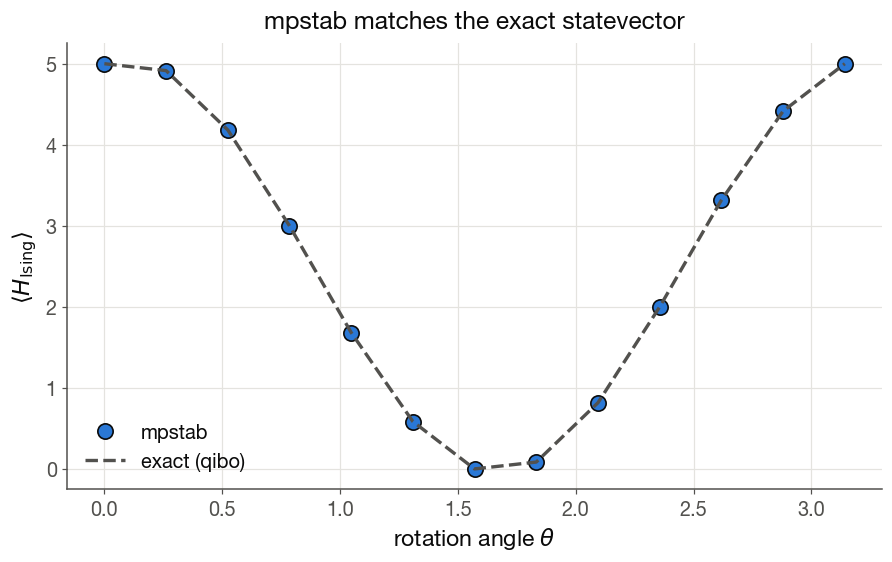

In [5]:
thetas = np.linspace(0, np.pi, 13)
mpstab_energy, exact_energy, n_magic = [], [], []
for theta in thetas:
    surrogate.set_parameters([theta] * nqubits)
    mpstab_energy.append(surrogate.expectation(ising))
    n_magic.append(surrogate.n_magic_gates)
    exact_energy.append(ising.expectation_from_state(build_circuit(theta)().state()))

print("magic gates along the sweep:", n_magic)

plt.plot(thetas, mpstab_energy, "o", label="mpstab")
plt.plot(thetas, exact_energy, "--", color=COLORS["gray"], label="exact (qibo)")
plt.xlabel(r"rotation angle $\theta$")
plt.ylabel(r"$\langle H_\mathrm{Ising} \rangle$")
plt.title("mpstab matches the exact statevector")
plt.legend()
plt.show()

## Clifford circuits are free

A circuit made only of Clifford gates never touches the MPS: it is simulated by the stabilizer engine alone, in polynomial time. This lets us prepare a 1000-qubit GHZ state and measure global observables in a fraction of a second, far beyond any statevector simulator.

In [6]:
n_ghz = 1000
ghz = Circuit(n_ghz)
ghz.add(gates.H(0))
for q in range(n_ghz - 1):
    ghz.add(gates.CNOT(q, q + 1))

start = time.time()
ghz_surrogate = HSMPO(ghz, progress=False)
print(f"magic gates: {ghz_surrogate.n_magic_gates}")
print(f"<Z...Z> = {ghz_surrogate.expectation('Z' * n_ghz):.3f}")
print(f"<X...X> = {ghz_surrogate.expectation('X' * n_ghz):.3f}")
print(f"<Z0>    = {ghz_surrogate.expectation('Z' + 'I' * (n_ghz - 1)):.3f}")
print(f"elapsed: {time.time() - start:.2f} s")

magic gates: 0
<Z...Z> = 1.000
<X...X> = 1.000
<Z0>    = 0.000
elapsed: 0.12 s


## Magic gates are what costs

Every magic gate becomes a Pauli rotation applied to the MPS, and each one can grow its bond dimension. A ready-made ansatz from `mpstab.models.ansatze` makes this easy to see: `HardwareEfficient` stacks layers of random $R_Y$ rotations (all magic) and rings of CZ gates (Clifford). Without a cap, the bond dimension of the MPS grows with the number of layers.

In [7]:
n_he = 12
for nlayers in [1, 2, 4, 6]:
    ansatz = HardwareEfficient(nqubits=n_he, nlayers=nlayers)
    hs = HSMPO(ansatz, progress=False)
    print(f"layers = {nlayers}: magic gates = {hs.n_magic_gates:3d}, "
          f"bond dimension = {hs.original_circuit_mps.max_bond()}")

layers = 1: magic gates =  12, bond dimension = 1
layers = 2: magic gates =  24, bond dimension = 16
layers = 4: magic gates =  48, bond dimension = 54


layers = 6: magic gates =  72, bond dimension = 64


### Trading accuracy for speed

For larger circuits we cap the MPS with `max_bond_dimension`. Truncation loses some of the state, and `return_fidelity=True` reports how much: the squared norm of the truncated MPS, which is 1 when nothing was discarded. Deeper circuits carry more magic and need a larger bond dimension to reach the same fidelity.

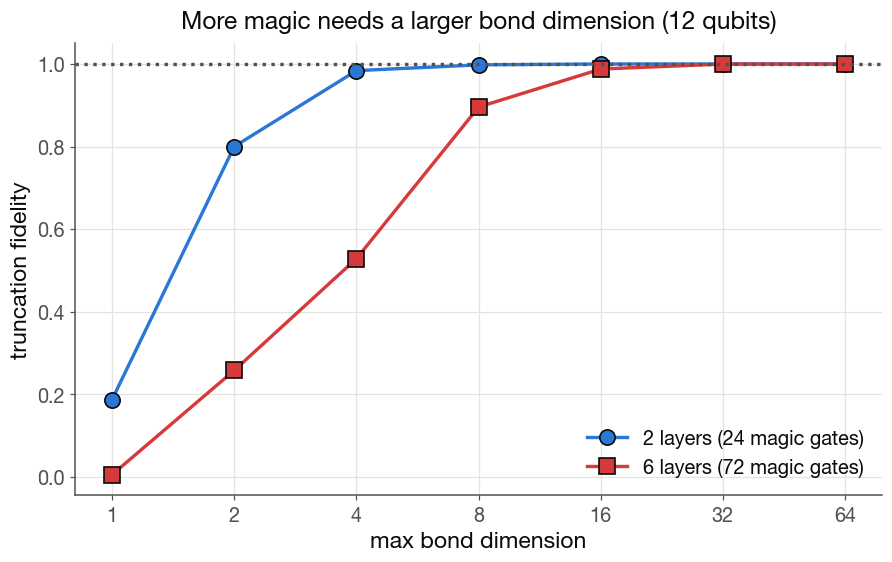

In [8]:
bond_dims = [1, 2, 4, 8, 16, 32, 64]
for nlayers, marker in [(2, "o"), (6, "s")]:
    ansatz = HardwareEfficient(nqubits=n_he, nlayers=nlayers)
    fidelities = []
    for chi in bond_dims:
        hs = HSMPO(ansatz, max_bond_dimension=chi, progress=False)
        _, fidelity = hs.expectation("Z" * n_he, return_fidelity=True)
        fidelities.append(abs(fidelity))
    plt.plot(bond_dims, fidelities, marker + "-", label=f"{nlayers} layers ({hs.n_magic_gates} magic gates)")

plt.axhline(1, ls=":", color=COLORS["gray"])
plt.xscale("log", base=2)
plt.xticks(bond_dims, bond_dims)
plt.xlabel("max bond dimension")
plt.ylabel("truncation fidelity")
plt.title(f"More magic needs a larger bond dimension ({n_he} qubits)")
plt.legend()
plt.show()

The fidelity also tells you how far to trust a truncated result. Let's compare the Ising energy of the 6-layer circuit at a few bond dimensions with the exact value. Since a surrogate without a cap is exact, as we checked above, we use it as the reference.

In [9]:
ising_he = hamiltonians.SymbolicHamiltonian(
    sum(Z(i) * Z(i + 1) for i in range(n_he - 1)) + 0.5 * sum(X(i) for i in range(n_he))
)
exact = HSMPO(ansatz, progress=False).expectation(ising_he)
print(f"exact energy: {exact:.6f}")
for chi in [4, 16, 64]:
    hs = HSMPO(ansatz, max_bond_dimension=chi, progress=False)
    value, fidelity = hs.expectation(ising_he, return_fidelity=True)
    print(f"chi = {chi:2d}: energy = {value:.6f}, |error| = {abs(value - exact):.1e}, fidelity = {abs(fidelity):.4f}")

exact energy: 0.522727
chi =  4: energy = 0.643416, |error| = 1.2e-01, fidelity = 0.5284
chi = 16: energy = 0.523519, |error| = 7.9e-04, fidelity = 0.9878
chi = 64: energy = 0.522727, |error| = 0.0e+00, fidelity = 1.0000


## Where to go next

You now know the core workflow: build a circuit, wrap it in `HSMPO`, and call `expectation`. The other tutorials build on it:

- **Pauli noise simulation**: noisy circuits with Pauli and coherent errors and readout errors.
- **Non-unital noise simulation**: relaxation and other Kraus channels, crosstalk, idle noise, preparation and asymmetric readout errors.
- **Data-driven error mitigation**: CDR and vnCDR, learning the noise from near-Clifford circuits that mpstab simulates cheaply.
- **Ground states with DMRG**: optimizing an MPS starting from an `HSMPO` surrogate to find ground-state energies.
- **State metrics**: measuring entanglement and magic of the states mpstab prepares.